In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import joblib
from sklearn.linear_model import RidgeCV,LassoCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

In [6]:
data = pd.read_csv('Dataset/Final Dataset.csv')
train_idx = pd.read_csv('Dataset/train_idx.csv').iloc[:,0].values
test_idx = pd.read_csv('Dataset/test_idx.csv').iloc[:,0].values

In [7]:
SEED = 25223721
for d in ["Figures", "Outputs", "Models"]:
    os.makedirs(d, exist_ok=True)

In [14]:
TARGET = 'BerRating'
X = data.drop(columns = [TARGET,'CO2Rating', 'EnergyRating']).copy()
cat_cols = X.select_dtypes(exclude = 'number').columns.tolist()
for c in cat_cols:
  X[c] = X[c].astype(str).str.strip().replace('nan',np.nan).astype(object)

X_tr, X_te = X.loc[train_idx],X.loc[test_idx]
y_tr,y_te = data.loc[train_idx,TARGET].values, data.loc[test_idx,TARGET].values

In [20]:
num_cols = [c for c in X.columns if c not in cat_cols]
skew = X_tr[num_cols].skew()
skewed = [c for c in num_cols if skew[c] > 1 and X_tr[c].min() >= 0]
not_skewed = [c for c in num_cols if c not in skewed]
print(f'Numeric Columns: {len(num_cols)}\nCategorical Columns: {len(cat_cols)}\nSkewed Columns: {len(skewed)}\nNon Skewed Columns: {len(not_skewed)}')

Numeric Columns: 29
Categorical Columns: 11
Skewed Columns: 18
Non Skewed Columns: 11


In [29]:
class Winsorizer(BaseEstimator, TransformerMixin):
  def __init__(self,lower = 0.01, upper = 0.99):
    self.lower = lower
    self.upper = upper

  def fit(self,X,y=None):
    X = np.asarray(X,dtype = float)
    self.lo_,self.hi_ = np.nanquantile(X,self.lower,axis = 0), np.nanquantile(X,self.upper,axis = 0)
    return self

  def transform(self,X):
    return np.clip(np.asarray(X,dtype=float),self.lo_,self.hi_)

  def get_feature_names_out(self,input_features = None):
    return np.asarray(input_features,dtype = object)

def num_steps(log = False):
   steps = [("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] if log else []
   return Pipeline(steps + [("imp", SimpleImputer(strategy="median")), ("win", Winsorizer()), ("sc", StandardScaler())])

pre = ColumnTransformer([
    ("numlog", num_steps(log=True), skewed),
    ("num", num_steps(), not_skewed),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                                           sparse_output=False))]), cat_cols)])

In [31]:
Z_tr = pre.fit_transform(X_tr)
Z_te = pre.transform(X_te)
feat_names = pre.get_feature_names_out()
print('Model Matrix: ',Z_tr.shape)

Model Matrix:  (190480, 99)


In [35]:
ridge = RidgeCV(alphas=np.logspace(-2,4,25),cv=5,scoring='neg_mean_squared_error').fit(Z_tr,y_tr)
lasso = LassoCV(alphas=np.logspace(-3,2,50),cv=5,max_iter=5000,n_jobs=-1,random_state=SEED).fit(Z_tr,y_tr)
print(f"Ridge alpha = {ridge.alpha_:.4g} | Lasso alpha = {lasso.alpha_:.4g}")

Ridge alpha = 5.623 | Lasso alpha = 0.001


In [39]:
def scores(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

models = {"Ridge": ridge, "Lasso": lasso}
cv_rmse = {"Ridge": float(np.sqrt(-ridge.best_score_)),
           "Lasso": float(np.sqrt(lasso.mse_path_.mean(axis=1).min()))}
rows = {}
for name, m in models.items():
    tr, te = scores(y_tr, m.predict(Z_tr)), scores(y_te, m.predict(Z_te))
    rows[name] = {"CV_RMSE": cv_rmse[name], "train_RMSE": tr["RMSE"], "test_RMSE": te["RMSE"],
                  "test_MAE": te["MAE"], "train_R2": tr["R2"], "test_R2": te["R2"]}
comp = pd.DataFrame(rows).T
comp["non_zero_coefs"] = [int((ridge.coef_ != 0).sum()), int((lasso.coef_ != 0).sum())]
comp["total_features"] = Z_tr.shape[1]
print(comp.round(3))
comp.to_csv("Outputs/linear_model_metrics.csv")

       CV_RMSE  train_RMSE  test_RMSE  ...  test_R2  non_zero_coefs  total_features
Ridge   24.552      24.537     24.663  ...    0.925              99              99
Lasso   24.552      24.537     24.663  ...    0.925              88              99

[2 rows x 8 columns]


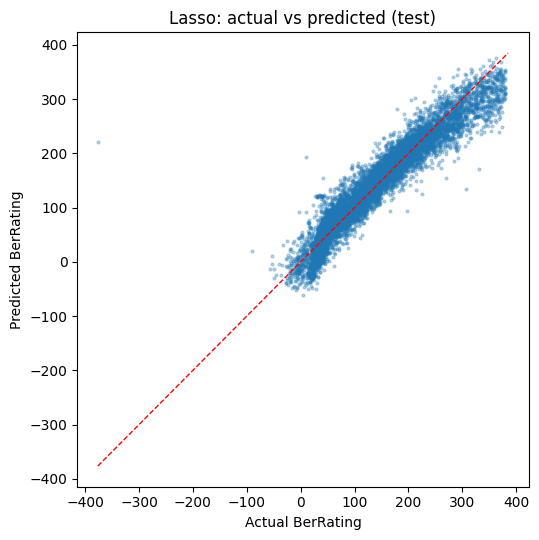

In [38]:
best_name = comp["test_RMSE"].idxmin()
pred_best = models[best_name].predict(Z_te)
rs = np.random.default_rng(SEED)
s = rs.choice(len(y_te), min(10000, len(y_te)), replace=False)
lim = [min(y_te.min(), pred_best.min()), max(y_te.max(), pred_best.max())]
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_te[s], pred_best[s], s=4, alpha=0.3)
plt.plot(lim, lim, "r--", lw=1)
plt.xlabel("Actual BerRating"); plt.ylabel("Predicted BerRating")
plt.title(f"{best_name}: actual vs predicted (test)")
plt.tight_layout(); plt.savefig("Figures/linear_actual_vs_predicted.png", dpi=200); plt.show()

In [41]:
def original_feature(name):
    if name.startswith("cat__"):
        matches = [c for c in cat_cols if name.startswith(f"cat__{c}_")]
        return max(matches, key=len) if matches else name
    return name.split("__", 1)[1]

coef = pd.DataFrame({"feature": feat_names, "original": [original_feature(n) for n in feat_names],
                     "lasso_coef": lasso.coef_, "ridge_coef": ridge.coef_})
coef["abs_lasso"] = coef["lasso_coef"].abs()
coef.sort_values("abs_lasso", ascending=False).to_csv("Outputs/linear_coefficients.csv", index=False)

by_feature = coef.groupby("original")["abs_lasso"].sum().sort_values(ascending=False)
zeroed = by_feature[by_feature == 0].index.tolist()
print(f"Lasso kept {int((lasso.coef_ != 0).sum())} of {len(lasso.coef_)} model columns.")
print("Original features removed completely by Lasso:", zeroed)
print("\nTop 15 original features (sum of absolute Lasso coefficients):")
print(by_feature.head(15).round(2).to_string())
print("\nLeast important features (non-zero, smallest first):")
print(by_feature[by_feature > 0].sort_values().head(10).round(3).to_string())
by_feature.to_csv("Outputs/lasso_feature_importance.csv")

Lasso kept 88 of 99 model columns.
Original features removed completely by Lasso: []

Top 15 original features (sum of absolute Lasso coefficients):
original
MainSpaceHeatingFuel      57.38
PredominantRoofType       49.22
MainWaterHeatingFuel      47.27
DwellingTypeDescr         37.63
WHMainSystemEff           29.47
GroundFloorArea(sq m)     28.43
CountyName                26.58
HSMainSystemEfficiency    26.31
SolarPVEnergyOutput       25.87
UValueWall                25.50
VentilationMethod         25.44
StructureType             18.96
RoofArea                  18.65
WallArea                  14.93
UValueRoof                14.56

Least important features (non-zero, smallest first):
original
RoomInRoofArea               0.040
UvalueDoor                   0.193
NoOfFansAndVents             0.288
Unnamed: 0                   0.748
NoOfOpenFlues                0.872
WindowArea                   0.935
PercentageDraughtStripped    0.968
NoOfSidesSheltered           1.119
InsulationThickness

In [42]:
joblib.dump({"pre": pre, "ridge": ridge, "lasso": lasso}, "Models/ridge_lasso_ber.joblib")

['Models/ridge_lasso_ber.joblib']